# 3D Gaussian fitting with a fully rotated ellipsoid

**Worked example: 6W1V DELFWT / omit-OEC difference-density maps**

This notebook follows the same workflow as `xfel_gaussian_fitting_tutorial.ipynb`: load a CCP4 map, detect separated positive and negative extrema, and fit each one inside a local sphere. The model here is a **fully rotated ellipsoidal Gaussian**. Its quadratic form is a full 3×3 covariance, so the principal axes need not lie along Cartesian $x,y,z$.

**Interpretation caution:** Difference density is signed, correlated, and affected by map coefficients, sharpening, truncation, and refinement. Principal widths and the Gaussian integral describe the map feature. They are not calibrated atomic displacement parameters or electron counts. The strongest peak is not Mn1 until its position is compared with structural coordinates.

**Workflow:** load map → inspect metadata → recover a synthetic rotated ellipsoid → detect separated extrema → nonlinear least-squares fit → visualize sections and elliptical contours → export reproducible results.

## 1. Select the map

On a local Jupyter installation, set `MAP_FILE` to a `.map` or `.ccp4` path, or leave it empty to use the first file in `../data/`. The 15 Å crop is small enough for a first run. A full unit-cell map has many more extrema; raise the detection threshold before fitting it.

In [15]:
from pathlib import Path

MAP_FILE = ''

if not MAP_FILE:
    candidates = list(Path('../data/').glob('*.map')) or list(Path('../data/').glob('*.ccp4'))
    MAP_FILE = str(candidates[0]) if candidates else ''
assert MAP_FILE and Path(MAP_FILE).exists(), 'Set MAP_FILE to an existing CCP4 map.'
print('Selected:', MAP_FILE)

Selected: ../data/6w1v_omitOEC_extended_15A.map


## 2. The fitted model

In Cartesian Å the signed peak is

$$\Delta\rho(\mathbf r)=b+A\exp\left(-\frac12(\mathbf r-\mathbf r_0)^\top\Sigma^{-1}(\mathbf r-\mathbf r_0)\right).$$

$\Sigma$ is a symmetric positive-definite covariance. Its level set $(\mathbf r-\mathbf r_0)^\top\Sigma^{-1}(\mathbf r-\mathbf r_0)=1$ is an ellipsoid. Diagonalizing $\Sigma=R\,\mathrm{diag}(s_1^2,s_2^2,s_3^2)\,R^\top$ gives the principal widths $s_i$ and a rotation $R$ whose columns are the principal axes. That is the fully rotated ellipsoid. The axis-aligned tutorial is the special case in which $R=I$.

A symmetric matrix has six independent entries, but it is a covariance only when it is positive definite. The fit therefore uses the unique Cholesky factor with a positive diagonal,

$$\Sigma=LL^\top,\qquad L=\begin{pmatrix}\ell_{00}&0&0\\ \ell_{10}&\ell_{11}&0\\ \ell_{20}&\ell_{21}&\ell_{22}\end{pmatrix},\qquad \ell_{ii}>0.$$

These six entries, together with $A$ and $b$, are the eight fitted parameters. The center $\mathbf r_0$ is not adjusted: it is fixed at the Cartesian position of the detected local maximum. Off-diagonal $\ell_{i0}$ are what allow the ellipsoid to rotate. Euler angles are not fitted directly: they are undefined for a sphere and interchangeable when two widths match. Orientation is reported after the fit by diagonalizing $\Sigma$.

Along principal axis $i$, $\mathrm{FWHM}_i=2\sqrt{2\ln 2}\,s_i$. The formal integral is

$$A(2\pi)^{3/2}\sqrt{\det\Sigma}=A(2\pi)^{3/2}\,\ell_{00}\ell_{11}\ell_{22}.$$

It is not a measured electron count. The equivalent isotropic width is $(s_1 s_2 s_3)^{1/3}$.

## 3. Reading CCP4 grids correctly

CCP4 header data specify stored-array order **columns / rows / sections** (MAPC/MAPR/MAPS), start indices (NCSTART/NRSTART/NSSTART), and the full unit-cell sampling (MX/MY/MZ). One must *not* assume that the raw array's first index means crystallographic X.

For a stored voxel index $q=(i,j,k)$, reorder using the CCP4 axis mapping, add the corresponding stored-grid starts, divide by the **XYZ** sampling, then multiply by the unit-cell orthogonalization matrix. This also handles non-orthogonal cells. We keep the original sampled region rather than expanding it into a unit cell filled with undefined voxels or connecting opposite edges of a finite map box.

Cartesian sections later in the notebook use the inverse of that map: Cartesian Å → fractional → stored-array index. Those indices are only for sampling the grid; the Gaussian itself is always evaluated in Cartesian Å.

In [16]:
"""
Fit significant positive/negative peaks to a fully rotated ellipsoidal Gaussian.

CCP4 MAPC/MAPR/MAPS order, map starts, and non-orthogonal cells are handled
explicitly. Fits use the sampled (nonperiodic) map region.
"""
import numpy as np
import pandas as pd
import gemmi
from scipy.ndimage import maximum_filter, minimum_filter, map_coordinates
from scipy.linalg import solve_triangular
from scipy.optimize import least_squares

FWHM_FACTOR = 2 * np.sqrt(2 * np.log(2))


def read_map(filename):
    m = gemmi.read_ccp4_map(str(filename), setup=False)
    rho = np.array(m.grid, copy=True, dtype=np.float32)
    # axis_positions()[x/y/z] is the stored-array axis for that fractional axis.
    xyz_axes = tuple(m.axis_positions())
    starts = np.array([m.header_i32(i) for i in (5, 6, 7)], dtype=float)
    sampling = np.array([m.header_i32(i) for i in (8, 9, 10)], dtype=float)
    cell = m.grid.unit_cell
    return rho, cell, starts, sampling, xyz_axes


def index_to_cart(index, cell, starts, sampling, xyz_axes):
    idx = np.asarray(index, dtype=float)
    fractional = (idx[..., list(xyz_axes)] + starts[list(xyz_axes)]) / sampling
    orth = np.asarray(cell.orth.mat)
    return fractional @ orth.T


def cart_to_index(xyz, cell, starts, sampling, xyz_axes):
    """Inverse of index_to_cart. Supports a single point or an array of points."""
    orth = np.asarray(cell.orth.mat, dtype=float)
    fractional = np.asarray(xyz, dtype=float) @ np.linalg.inv(orth).T
    index = np.empty(np.shape(xyz), dtype=float)
    for frac_axis, array_axis in enumerate(xyz_axes):
        index[..., array_axis] = fractional[..., frac_axis] * sampling[frac_axis] - starts[array_axis]
    return index


def detect_peaks(rho, zmin=3.0, min_distance=1.5, n_each=15,
                 cell=None, starts=None, sampling=None, xyz_axes=None):
    sigma = float(np.nanstd(rho))
    if sigma <= 0 or not np.isfinite(sigma):
        raise ValueError('The map has no finite density variation.')
    valid = np.isfinite(rho)
    largest = maximum_filter(np.where(valid, rho, -np.inf), size=3, mode='constant', cval=-np.inf)
    smallest = minimum_filter(np.where(valid, rho, np.inf), size=3, mode='constant', cval=np.inf)
    peaks = []
    for sign, mask in [('positive', valid & (rho >= zmin * sigma) & (rho == largest)),
                       ('negative', valid & (rho <= -zmin * sigma) & (rho == smallest))]:
        points = np.argwhere(mask)
        if len(points) == 0:
            continue
        order = np.argsort(-np.abs(rho[tuple(points.T)]))
        selected_xyz = []
        for p in points[order]:
            xyz = index_to_cart(p, cell, starts, sampling, xyz_axes)
            if all(np.linalg.norm(xyz - old) >= min_distance for old in selected_xyz):
                peaks.append((sign, tuple(int(x) for x in p), float(rho[tuple(p)]), xyz))
                selected_xyz.append(xyz)
                if len(selected_xyz) >= n_each:
                    break
    return peaks, sigma


def gaussian_density(xyz, amplitude, center, cholesky, background):
    """Evaluate b + A exp(-1/2 ||L^{-1}(r-r0)||^2). cholesky is lower-triangular L."""
    delta = np.asarray(xyz, dtype=float) - np.asarray(center, dtype=float)
    local = solve_triangular(cholesky, np.swapaxes(delta, -1, 0), lower=True, check_finite=False)
    quadratic = np.sum(local * local, axis=0)
    return background + amplitude * np.exp(-0.5 * quadratic)


def cholesky_matrix(parameters):
    """Pack parameters [A, L00, L10, L20, L11, L21, L22, b]. The center is not a parameter."""
    return np.array([
        [parameters[1], 0.0, 0.0],
        [parameters[2], parameters[4], 0.0],
        [parameters[3], parameters[5], parameters[6]],
    ], dtype=float)


def principal_frame(covariance):
    """Descending principal widths and a right-handed eigenframe of Σ.

    Each axis is first flipped so its largest component is positive. If that
    makes a left-handed frame, the minor axis is flipped.
    """
    values, vectors = np.linalg.eigh(0.5 * (covariance + covariance.T))
    order = np.argsort(values)[::-1]
    values = np.clip(values[order], 0.0, None)
    vectors = vectors[:, order]
    for i in range(3):
        dominant = int(np.argmax(np.abs(vectors[:, i])))
        if vectors[dominant, i] < 0:
            vectors[:, i] *= -1
    if np.linalg.det(vectors) < 0:
        vectors[:, 2] *= -1
    return np.sqrt(values), vectors


def fit_ellipsoid(xyz, y, sign, xyz0, radius, step, peak_value):
    """Fit one full-covariance Gaussian with the center fixed at xyz0.

    xyz0 is the Cartesian position of the detected maximum. Parameter order is
    amplitude, Cholesky factor of Σ, and background. The diagonal of L is kept
    positive, which forces Σ to stay positive definite.
    """
    xyz = np.asarray(xyz, dtype=float)
    y = np.asarray(y, dtype=float)
    center = np.asarray(xyz0, dtype=float)
    if len(y) < 15:
        return None
    shell = np.linalg.norm(xyz - center, axis=1) > 0.75 * radius
    local_bg = float(np.median(y[shell])) if np.any(shell) else 0.0
    amp0 = peak_value - local_bg
    amp0 = max(amp0, 1e-3) if sign == 'positive' else min(amp0, -1e-3)
    smin = max(0.15, step / 3.0)
    smax = 2.0 * radius
    # L_ii ~ width (Å). Off-diagonal entries, also in Å, rotate and couple the axes.
    initial = np.array([amp0, 0.8, 0.0, 0.0, 0.8, 0.0, 0.8, local_bg], dtype=float)
    lower = np.array([
        0.0 if sign == 'positive' else -np.inf,
        smin, -smax, -smax, smin, -smax, smin, -np.inf,
    ])
    upper = np.array([
        np.inf if sign == 'positive' else 0.0,
        smax, smax, smax, smax, smax, smax, np.inf,
    ])
    initial = np.clip(initial, lower + 1e-8, upper - 1e-8)

    def residual(parameters):
        return gaussian_density(xyz, parameters[0], center, cholesky_matrix(parameters), parameters[7]) - y

    fit = least_squares(residual, initial, bounds=(lower, upper), method='trf', x_scale='jac', max_nfev=4096)
    parameters = fit.x
    cholesky = cholesky_matrix(parameters)
    covariance = cholesky @ cholesky.T
    widths, axes = principal_frame(covariance)
    # residual() returns model - data, so fit.fun is that vector.
    rss = float(np.dot(fit.fun, fit.fun))
    total = float(np.dot(y - y.mean(), y - y.mean()))
    return {
        'sign': sign,
        'map_peak': float(peak_value),
        'x_A': float(center[0]),
        'y_A': float(center[1]),
        'z_A': float(center[2]),
        'amplitude': float(parameters[0]),
        'background': float(parameters[7]),
        'sigma_1_A': float(widths[0]),
        'sigma_2_A': float(widths[1]),
        'sigma_3_A': float(widths[2]),
        'fwhm_1_A': float(FWHM_FACTOR * widths[0]),
        'fwhm_2_A': float(FWHM_FACTOR * widths[1]),
        'fwhm_3_A': float(FWHM_FACTOR * widths[2]),
        'equiv_sigma_A': float(np.prod(widths) ** (1.0 / 3.0)),
        'cov_xx': float(covariance[0, 0]),
        'cov_yy': float(covariance[1, 1]),
        'cov_zz': float(covariance[2, 2]),
        'cov_xy': float(covariance[0, 1]),
        'cov_xz': float(covariance[0, 2]),
        'cov_yz': float(covariance[1, 2]),
        'L00': float(cholesky[0, 0]),
        'L10': float(cholesky[1, 0]),
        'L20': float(cholesky[2, 0]),
        'L11': float(cholesky[1, 1]),
        'L21': float(cholesky[2, 1]),
        'L22': float(cholesky[2, 2]),
        'v1_x': float(axes[0, 0]), 'v1_y': float(axes[1, 0]), 'v1_z': float(axes[2, 0]),
        'v2_x': float(axes[0, 1]), 'v2_y': float(axes[1, 1]), 'v2_z': float(axes[2, 1]),
        'v3_x': float(axes[0, 2]), 'v3_y': float(axes[1, 2]), 'v3_z': float(axes[2, 2]),
        'condition_number': float(np.linalg.cond(covariance)),
        'n_at_bound': int(np.count_nonzero(fit.active_mask)),
        'integrated_gaussian': float(parameters[0] * (2 * np.pi) ** 1.5 * np.prod(np.diag(cholesky))),
        'r2': float(1 - rss / total) if total > 0 else np.nan,
        'rmse': float(np.sqrt(rss / len(y))),
        'n_voxels': int(len(y)),
        'success': bool(fit.success),
    }


def fit_peak(rho, peak, cell, starts, sampling, xyz_axes, radius=2.5):
    sign, idx, peak_value, xyz0 = peak
    origin = index_to_cart(np.zeros(3), cell, starts, sampling, xyz_axes)
    basis = np.stack([
        index_to_cart(np.eye(3)[j], cell, starts, sampling, xyz_axes) - origin
        for j in range(3)
    ])
    spacings = np.linalg.norm(basis, axis=1)
    offsets = np.ceil(radius / spacings).astype(int) + 2
    low = np.maximum(0, np.asarray(idx) - offsets)
    high = np.minimum(np.array(rho.shape), np.asarray(idx) + offsets + 1)
    coords = np.indices(tuple(high - low)).reshape(3, -1).T + low
    xyz = index_to_cart(coords, cell, starts, sampling, xyz_axes)
    distance = np.linalg.norm(xyz - xyz0, axis=1)
    values = rho[tuple(coords.T)]
    keep = (distance <= radius) & np.isfinite(values)
    fitted = fit_ellipsoid(xyz[keep], values[keep], sign, xyz0, radius, float(np.min(spacings)), peak_value)
    if fitted is None:
        return None
    fitted.update(raw_i=idx[0], raw_j=idx[1], raw_k=idx[2])
    return fitted


def cholesky_from_row(row):
    return np.array([
        [row.L00, 0.0, 0.0],
        [row.L10, row.L11, 0.0],
        [row.L20, row.L21, row.L22],
    ], dtype=float)


def covariance_from_row(row):
    factor = cholesky_from_row(row)
    return factor @ factor.T


def analyze(path, n_each=12, threshold=4, fit_radius=2.5, min_distance=2.0):
    rho, cell, starts, sampling, axes = read_map(path)
    peaks, global_sigma = detect_peaks(rho, threshold, min_distance, n_each, cell, starts, sampling, axes)
    results = []
    for peak in peaks:
        result = fit_peak(rho, peak, cell, starts, sampling, axes, fit_radius)
        if result:
            results.append(result)
    frame = pd.DataFrame(results)
    info = {
        'shape': rho.shape,
        'cell': str(cell),
        'global_sigma': global_sigma,
        'n_candidates': len(peaks),
        'axis_positions': axes,
        'starts': starts.tolist(),
        'sampling': sampling.tolist(),
    }
    return frame, info

## 4. Synthetic recovery of a known rotated ellipsoid

Before trusting map fits, recover a Gaussian whose covariance is known and whose principal axes are **not** aligned with $x,y,z$. The samples are a noisy Cartesian grid, and the true center is placed on a grid node. The fit holds the center at the sample of largest density — the detected maximum — and starts from a spherical Cholesky factor.

In [17]:
rng = np.random.default_rng(0)
grid = np.linspace(-3.2, 3.2, 33)
synthetic_xyz = np.stack(np.meshgrid(grid, grid, grid, indexing='ij'), -1).reshape(-1, 3)

angle = np.deg2rad(35.0)
axis = np.array([0.2, 0.5, 1.0])
axis = axis / np.linalg.norm(axis)
skew = np.array([[0, -axis[2], axis[1]], [axis[2], 0, -axis[0]], [-axis[1], axis[0], 0]])
true_rotation = np.eye(3) + np.sin(angle) * skew + (1 - np.cos(angle)) * (skew @ skew)
true_widths = np.array([1.15, 0.48, 0.75])
true_covariance = true_rotation @ np.diag(true_widths ** 2) @ true_rotation.T
true_center = np.array([0.2, -0.2, 0.0])  # a node of `grid`
true_amplitude, true_background = 3.2, -0.15
true_cholesky = np.linalg.cholesky(true_covariance)

inside = np.linalg.norm(synthetic_xyz, axis=1) <= 2.8
synthetic_xyz = synthetic_xyz[inside]
clean = gaussian_density(synthetic_xyz, true_amplitude, true_center, true_cholesky, true_background)
synthetic_y = clean + rng.normal(0.0, 0.03, size=len(clean))
peak_index = int(np.argmax(synthetic_y))
detected_center = synthetic_xyz[peak_index]
recovered = fit_ellipsoid(
    synthetic_xyz, synthetic_y, 'positive', detected_center, radius=2.8, step=0.2,
    peak_value=float(synthetic_y[peak_index]),
)
fitted_covariance = covariance_from_row(pd.Series(recovered))
fitted_axes = np.column_stack([
    [recovered['v1_x'], recovered['v1_y'], recovered['v1_z']],
    [recovered['v2_x'], recovered['v2_y'], recovered['v2_z']],
    [recovered['v3_x'], recovered['v3_y'], recovered['v3_z']],
])
# Match each fitted axis to a true principal axis. Signs of eigenvectors are conventional.
true_axes = principal_frame(true_covariance)[1]
alignment = np.max(np.abs(true_axes.T @ fitted_axes), axis=0)
reported_center = np.array([recovered['x_A'], recovered['y_A'], recovered['z_A']])
center_shift = np.linalg.norm(reported_center - detected_center)
detection_offset = np.linalg.norm(detected_center - true_center)
covariance_error = np.linalg.norm(fitted_covariance - true_covariance)

print('True Σ (Å²)')
print(np.array2string(true_covariance, precision=3, suppress_small=True))
print('Fitted Σ (Å²)')
print(np.array2string(fitted_covariance, precision=3, suppress_small=True))
print('detected maximum', np.round(detected_center, 3), 'true center', true_center)
print(f'center held fixed (shift {center_shift:.2e} Å); detection offset from truth {detection_offset:.4f} Å')
print(f'amplitude {recovered["amplitude"]:.3f} (true {true_amplitude:.3f}), '
      f'background {recovered["background"]:.3f} (true {true_background:.3f})')
print('principal widths true', np.sort(true_widths)[::-1],
      'fitted', [recovered['sigma_1_A'], recovered['sigma_2_A'], recovered['sigma_3_A']])
print('minimum |cos| between matched principal axes', float(alignment.min()))
assert recovered['success']
assert center_shift < 1e-12
assert detection_offset < 1e-12
assert covariance_error < 0.05
assert abs(recovered['amplitude'] - true_amplitude) < 0.1
assert alignment.min() > 0.99
print('Synthetic rotated ellipsoid recovered.')

True Σ (Å²)
[[ 0.999  0.465 -0.113]
 [ 0.465  0.525 -0.137]
 [-0.113 -0.137  0.591]]
Fitted Σ (Å²)
[[ 0.998  0.465 -0.113]
 [ 0.465  0.526 -0.137]
 [-0.113 -0.137  0.591]]
detected maximum [ 0.2 -0.2  0. ] true center [ 0.2 -0.2  0. ]
center held fixed (shift 0.00e+00 Å); detection offset from truth 0.0000 Å
amplitude 3.201 (true 3.200), background -0.150 (true -0.150)
principal widths true [1.15 0.75 0.48] fitted [1.1500198587529984, 0.7497933763728403, 0.4803347932737759]
minimum |cos| between matched principal axes 0.9999982419768801
Synthetic rotated ellipsoid recovered.


In [18]:
rho, cell, starts, sampling, axes = read_map(MAP_FILE)
print('Map shape (stored axes):', rho.shape)
print('Unit cell:', cell)
print('XYZ indices in stored array:', axes)
print('Stored starts:', starts)
print('Unit-cell grid sampling (XYZ):', sampling)
print('Density min/max:', float(rho.min()), float(rho.max()))
print('Map mean / SD:', float(rho.mean()), float(rho.std()))
origin = index_to_cart([0, 0, 0], cell, starts, sampling, axes)
print('First stored-voxel Cartesian coordinate (Å):', origin)
roundtrip = cart_to_index(index_to_cart([[0, 0, 0], [4, 2, 7]], cell, starts, sampling, axes),
                          cell, starts, sampling, axes)
print('Index round-trip max error:', float(np.max(np.abs(roundtrip - np.array([[0, 0, 0], [4, 2, 7]])))))

Map shape (stored axes): (49, 49, 49)
Unit cell: <gemmi.UnitCell(116.958, 221.646, 307.786, 90, 90, 90)>
XYZ indices in stored array: (1, 0, 2)
Stored starts: [ 39. -74. 547.]
Unit-cell grid sampling (XYZ): [180. 352. 484.]
Density min/max: -0.36780011653900146 2.9782397747039795
Map mean / SD: 0.00017866799316834658 0.11414206773042679
First stored-voxel Cartesian coordinate (Å): [-48.08273333  24.55736932 347.84906502]
Index round-trip max error: 1.4210854715202004e-14


## 5. Detecting the strongest peaks

A candidate positive (negative) peak must be at least as large (small) as its 26 nearest grid neighbors and exceed the selected threshold in units of the **map-wide standard deviation**. We then greedily retain peaks separated by at least `MIN_DISTANCE` Å. A global map SD is a screening heuristic: a tightly cropped area, molecular mask, or map with large peaks can have a different noise distribution; a robust local-noise estimate may be preferable for quantitative significance.

Use a higher threshold for a larger map. `N_EACH` is a separate maximum for positive and negative peaks.

In [19]:
THRESHOLD_SIGMA = 4.0 if rho.size < 1_000_000 else 8.0
N_EACH = 12
MIN_DISTANCE = 2.0  # Angstrom
FIT_RADIUS = 2.5    # Angstrom

peaks, global_sigma = detect_peaks(
    rho, THRESHOLD_SIGMA, MIN_DISTANCE, N_EACH, cell, starts, sampling, axes,
)
print(f'Found {len(peaks)} candidates; density SD={global_sigma:.6g}')
for sign, ijk, density, xyz in peaks:
    print(f'{sign:8s} grid={ijk} raw={density:+.5f} XYZ={np.round(xyz, 3)}')

Found 4 candidates; density SD=0.114142
positive grid=(23, 21, 28) raw=+2.97824 XYZ=[-34.438  39.04  365.655]
positive grid=(22, 25, 29) raw=+2.82549 XYZ=[-31.839  38.41  366.291]
positive grid=(19, 23, 26) raw=+2.59115 XYZ=[-33.138  36.521 364.383]
positive grid=(19, 22, 22) raw=+2.37569 XYZ=[-33.788  36.521 361.839]


## 6. Local nonlinear least squares

Each fit uses finite voxels inside a sphere of radius `FIT_RADIUS` Å around the detected extremum. The Gaussian center is that extremum's Cartesian coordinate and is held fixed. `scipy.optimize.least_squares` (trust-region reflective) adjusts the other eight parameters:

- amplitude $A$, positive for a positive peak and negative for a negative peak
- Cholesky diagonal $\ell_{ii}$ in $[\max(0.15,\Delta/3),\,2\times\mathrm{FIT\_RADIUS}]$ Å, where $\Delta$ is the finest grid spacing
- Cholesky off-diagonal entries in $\pm 2\times\mathrm{FIT\_RADIUS}$ Å
- a constant background

The initial factor is $L=0.8\,I$, a sphere. Anisotropy and rotation are introduced only if they reduce the residual. $\Sigma=LL^\top$ is positive definite throughout. Because the center cannot move, a grid maximum that sits on a merged feature stays on the detected voxel; the ellipsoid then describes the density around that voxel.

$R^2=1-\mathrm{RSS}/\mathrm{TSS}$ and the residual RMS are computed inside the fit sphere. They do **not** account for spatial correlation of map noise. `n_at_bound` counts parameters sitting on a bound. A principal width near the upper limit, or a large condition number $\lambda_\mathrm{max}/\lambda_\mathrm{min}$, means the window is too small to pin down that axis: the feature is wider than the sphere, or it is merged with a neighbor. Nearly equal principal widths make the eigenvectors in that plane weakly determined; the covariance itself is still well defined.

In [20]:
rows = [fit_peak(rho, peak, cell, starts, sampling, axes, FIT_RADIUS) for peak in peaks]
results = pd.DataFrame([row for row in rows if row is not None])
summary_columns = [
    'sign', 'x_A', 'y_A', 'z_A', 'amplitude', 'background',
    'sigma_1_A', 'sigma_2_A', 'sigma_3_A', 'equiv_sigma_A',
    'v1_x', 'v1_y', 'v1_z', 'condition_number', 'n_at_bound', 'r2', 'rmse',
]
covariance_columns = [
    'sign', 'cov_xx', 'cov_yy', 'cov_zz', 'cov_xy', 'cov_xz', 'cov_yz',
    'integrated_gaussian', 'fwhm_1_A', 'fwhm_2_A', 'fwhm_3_A', 'success',
]
if len(results):
    display(results[summary_columns].round(4))
    display(results[covariance_columns].round(4))
else:
    print('No fitted peaks: reduce the threshold or check the map.')

,sign,x_A,y_A,z_A,amplitude,background,sigma_1_A,sigma_2_A,sigma_3_A,equiv_sigma_A,v1_x,v1_y,v1_z,condition_number,n_at_bound,r2,rmse
0,positive,-34.4376,39.0399,365.6549,2.7125,-0.0318,1.8206,1.0238,0.9322,1.2022,0.9489,-0.3010,0.0950,3.8145,0,0.6104,0.4671
1,positive,-31.8386,38.4102,366.2908,2.5097,-0.0144,1.6282,1.0992,0.9224,1.1818,0.8300,0.1215,0.5444,3.1161,0,0.4836,0.5440
2,positive,-33.1381,36.5212,364.3830,2.2698,-0.0779,3.5564,1.1995,1.1031,1.6758,0.0305,0.5664,0.8236,10.3937,0,0.5798,0.4547
3,positive,-33.7879,36.5212,361.8393,2.3057,-0.1226,2.0772,1.1971,0.8714,1.2940,0.3789,-0.0113,0.9254,5.6825,0,0.6540,0.3787


,sign,cov_xx,cov_yy,cov_zz,cov_xy,cov_xz,cov_yz,integrated_gaussian,fwhm_1_A,fwhm_2_A,fwhm_3_A,success
0,positive,3.0855,1.2511,0.8949,-0.6500,0.2279,-0.0448,74.2228,4.2871,2.4108,2.1951,True
1,positive,2.1312,1.1596,1.4192,0.0751,0.7759,0.2185,65.2491,3.8341,2.5884,2.1720,True
2,positive,1.4277,4.9008,8.9750,0.1399,0.3196,5.3229,168.2297,8.3746,2.8247,2.5976,True
3,positive,1.4817,1.1829,3.8423,-0.3146,1.1563,0.0906,78.6790,4.8914,2.8188,2.0519,True


## 7. Sections through the data and the ellipsoid

The first row of each figure is the stored-array section through the detected grid peak. Its horizontal and vertical axes are array axes 0 and 1, which need not be Cartesian $x$ and $y$. Observed values, the full-covariance model, and the residual are sampled on those voxels.

The second row shows Cartesian $xy$, $xz$, and $yz$ planes through the detected maximum, which is the fixed Gaussian center. Coordinates on those panels are Å relative to the center. The solid curve is the elliptical section of $(\mathbf r-\mathbf r_0)^\top\Sigma^{-1}(\mathbf r-\mathbf r_0)=1$ (the $1\sigma$ ellipsoid). The dashed curve is the $2\sigma$ section, where the quadratic form equals 4. A circle would mean equal widths in that plane; a tilted ellipse is the rotation this model adds.

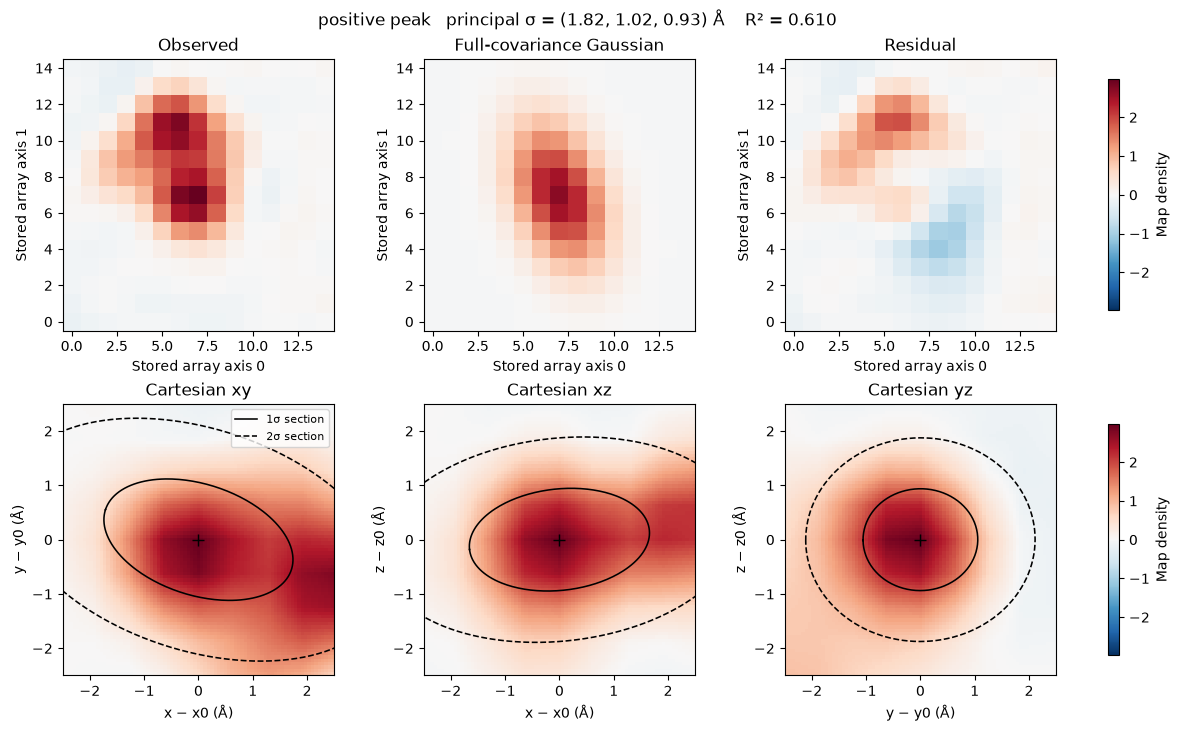

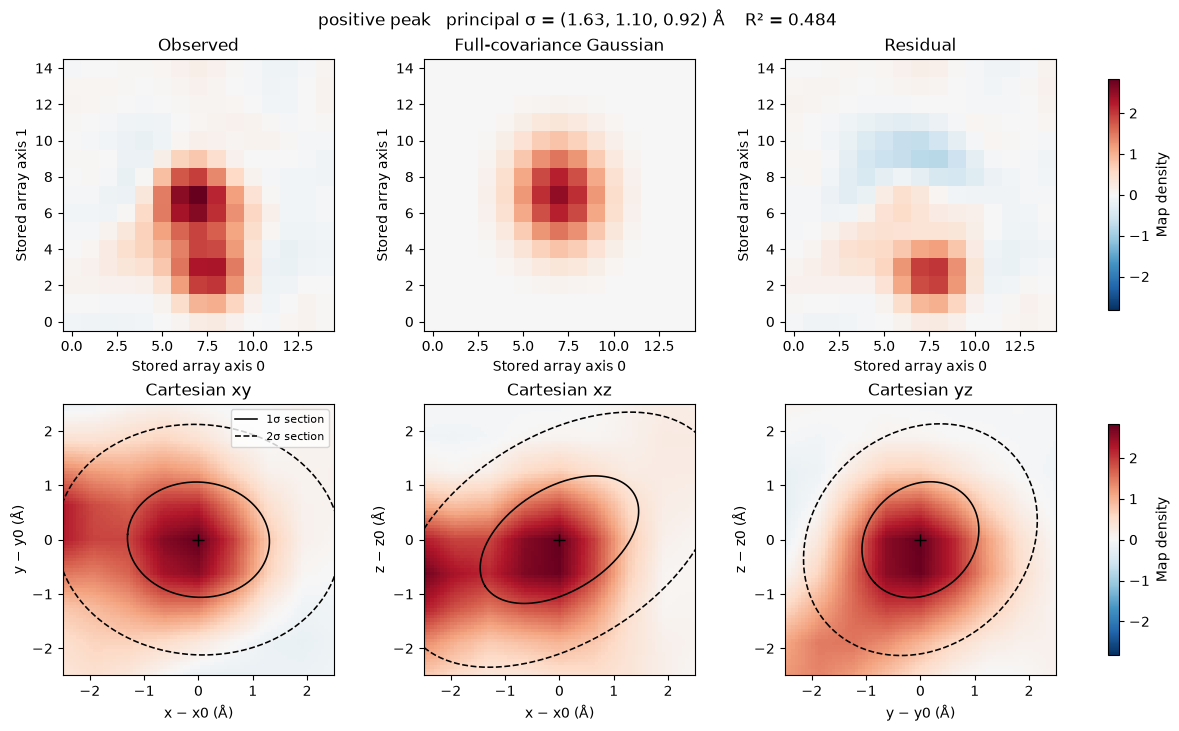

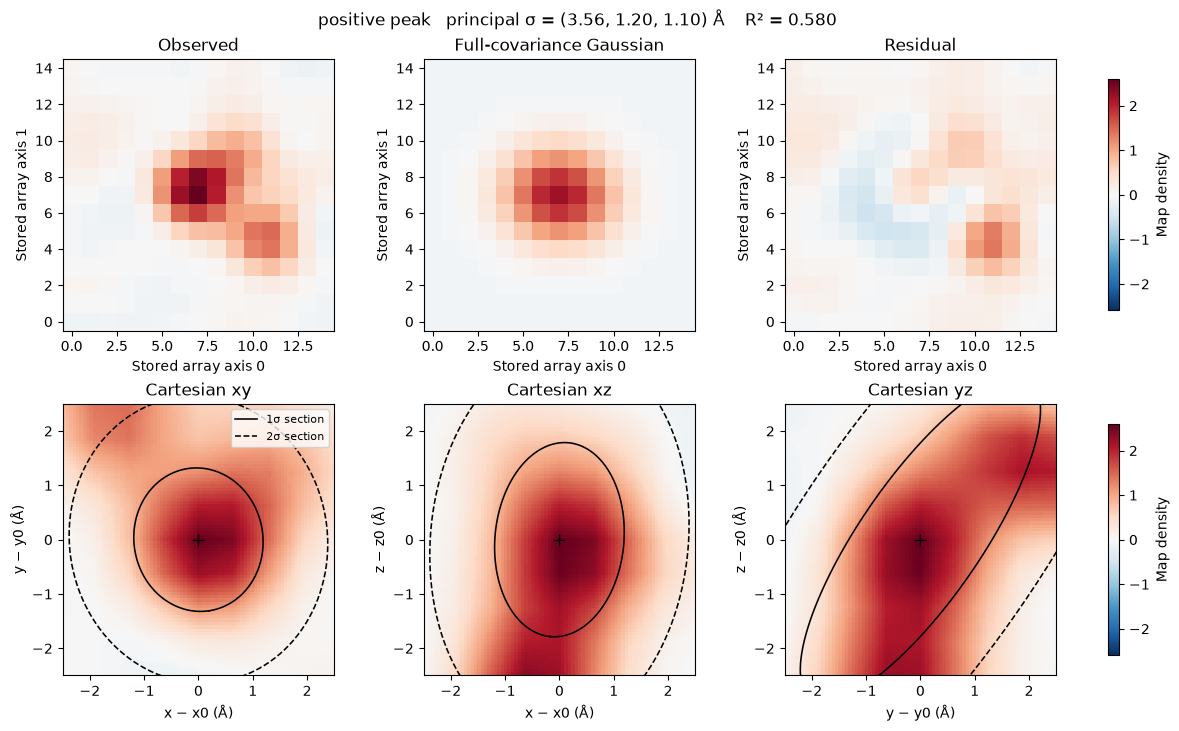

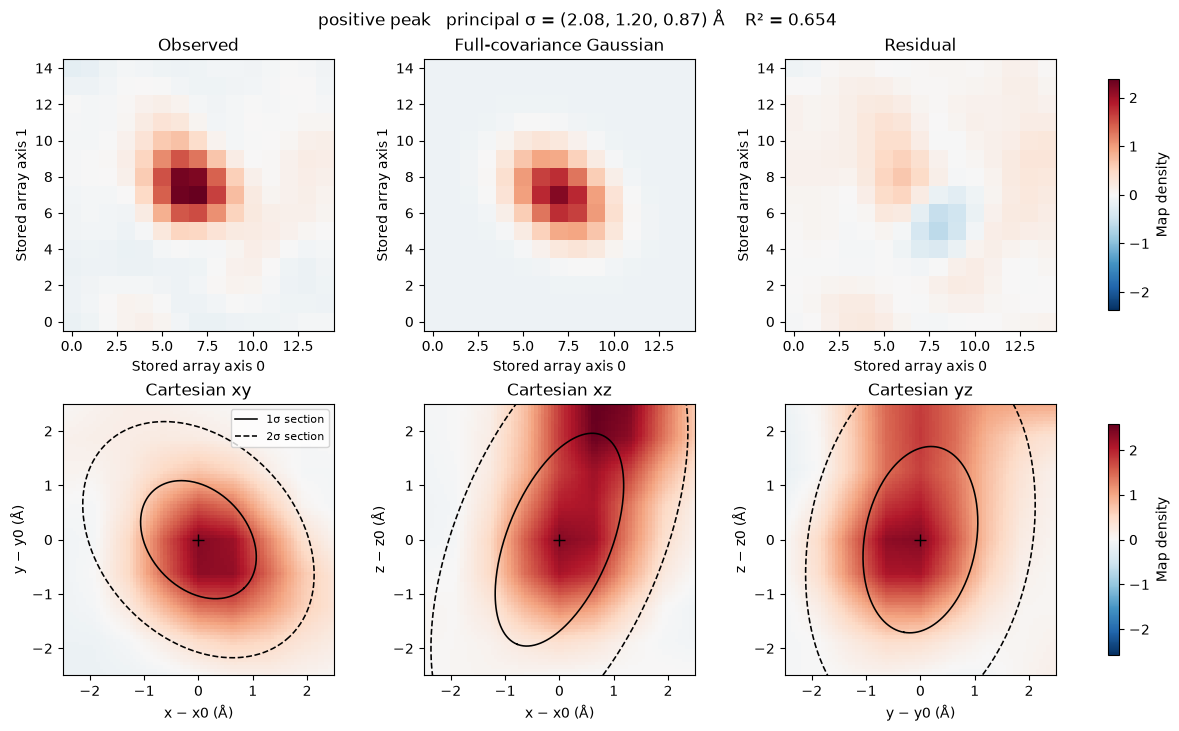

In [21]:
import matplotlib.pyplot as plt


def section_ellipse(covariance, axis_u, axis_v, nsigma=1.0, n=256):
    """Elliptical section of the nsigma-Mahalanobis ellipsoid by a plane through the center."""
    plane = np.column_stack([np.asarray(axis_u, float), np.asarray(axis_v, float)])
    metric = plane.T @ np.linalg.inv(covariance) @ plane
    values, vectors = np.linalg.eigh(0.5 * (metric + metric.T))
    if np.any(values <= 1e-10):
        return None
    theta = np.linspace(0, 2 * np.pi, n)
    circle = np.stack([np.cos(theta), np.sin(theta)], axis=0)
    return nsigma * (vectors @ (circle / np.sqrt(values)[:, None]))


def cartesian_section(center, axis_u, axis_v, half, n):
    coordinate = np.linspace(-half, half, n)
    uu, vv = np.meshgrid(coordinate, coordinate, indexing='xy')
    points = center + uu[..., None] * axis_u + vv[..., None] * axis_v
    index = cart_to_index(points, cell, starts, sampling, axes)
    sampled = map_coordinates(
        rho, [index[..., 0], index[..., 1], index[..., 2]],
        order=1, mode='constant', cval=np.nan,
    )
    return sampled


planes = [
    ('xy', np.array([1.0, 0.0, 0.0]), np.array([0.0, 1.0, 0.0]), 'x − x0 (Å)', 'y − y0 (Å)'),
    ('xz', np.array([1.0, 0.0, 0.0]), np.array([0.0, 0.0, 1.0]), 'x − x0 (Å)', 'z − z0 (Å)'),
    ('yz', np.array([0.0, 1.0, 0.0]), np.array([0.0, 0.0, 1.0]), 'y − y0 (Å)', 'z − z0 (Å)'),
]

if len(results) == 0:
    print('No detected peak to plot')
else:
    for _, best in results.iterrows():
        ijk = np.array([int(best.raw_i), int(best.raw_j), int(best.raw_k)])
        ii = np.arange(max(0, ijk[0] - 7), min(rho.shape[0], ijk[0] + 8))
        jj = np.arange(max(0, ijk[1] - 7), min(rho.shape[1], ijk[1] + 8))
        II, JJ = np.meshgrid(ii, jj, indexing='ij')
        coords = np.column_stack([II.ravel(), JJ.ravel(), np.full(II.size, ijk[2])])
        points = index_to_cart(coords, cell, starts, sampling, axes)
        center = np.array([best.x_A, best.y_A, best.z_A])
        factor = cholesky_from_row(best)
        covariance = factor @ factor.T
        predicted = gaussian_density(points, best.amplitude, center, factor, best.background).reshape(II.shape)
        observed = rho[II, JJ, ijk[2]]

        fig, ax = plt.subplots(2, 3, figsize=(12, 7.2), constrained_layout=True)
        scale = max(np.nanmax(np.abs(observed)), np.nanmax(np.abs(predicted)))
        scale = float(scale) if np.isfinite(scale) and scale > 0 else 1.0
        for panel, image, title in zip(
            ax[0],
            [observed, predicted, observed - predicted],
            ['Observed', 'Full-covariance Gaussian', 'Residual'],
        ):
            image_artist = panel.imshow(
                image.T, origin='lower', cmap='RdBu_r', vmin=-scale, vmax=scale, aspect='equal',
            )
            panel.set_title(title)
            panel.set_xlabel('Stored array axis 0')
            panel.set_ylabel('Stored array axis 1')
        fig.colorbar(image_artist, ax=ax[0], shrink=0.85, label='Map density')

        sections = [cartesian_section(center, eu, ev, FIT_RADIUS, 81) for _, eu, ev, _, _ in planes]
        finite = np.concatenate([np.abs(section[np.isfinite(section)]) for section in sections])
        plane_scale = float(np.max(finite)) if len(finite) else 1.0
        for panel, section, (name, eu, ev, xlabel, ylabel) in zip(ax[1], sections, planes):
            plane_artist = panel.imshow(
                section, origin='lower', cmap='RdBu_r', vmin=-plane_scale, vmax=plane_scale,
                extent=[-FIT_RADIUS, FIT_RADIUS, -FIT_RADIUS, FIT_RADIUS], aspect='equal',
            )
            for nsigma, style in ((1.0, '-'), (2.0, '--')):
                ellipse = section_ellipse(covariance, eu, ev, nsigma=nsigma)
                if ellipse is not None:
                    panel.plot(ellipse[0], ellipse[1], 'k', ls=style, lw=1.15,
                               label=f'{nsigma:.0f}σ section' if name == 'xy' else None)
            panel.plot(0, 0, 'k+', ms=8)
            panel.set_xlim(-FIT_RADIUS, FIT_RADIUS)
            panel.set_ylim(-FIT_RADIUS, FIT_RADIUS)
            panel.set_title(f'Cartesian {name}')
            panel.set_xlabel(xlabel)
            panel.set_ylabel(ylabel)
        ax[1, 0].legend(loc='upper right', fontsize=8, frameon=True)
        fig.colorbar(plane_artist, ax=ax[1], shrink=0.85, label='Map density')
        fig.suptitle(
            f'{best.sign} peak   principal σ = '
            f'({best.sigma_1_A:.2f}, {best.sigma_2_A:.2f}, {best.sigma_3_A:.2f}) Å'
            f'    R² = {best.r2:.3f}'
        )
        plt.show()

## 8. Export results

The CSV contains the detected extremum, its Cartesian position (the fixed Gaussian center), amplitude, background, principal widths and FWHMs, the six unique covariance entries, the Cholesky factor actually optimized, the principal-axis direction cosines, the condition number, the signed Gaussian integral, and the fit diagnostics.

Positions are in the map's stored crystallographic frame and may lie outside the conventional unit cell. Convert to symmetry-equivalent positions only after choosing the structural frame and reference model. Principal axes are ordered from largest to smallest width. Their signs follow the convention in `principal_frame` (right-handed, and the largest component of each of the first two axes is positive).

In [ ]:
OUTFILE = '6w1v_fitted_full_covariance_peaks.csv'
results.to_csv(OUTFILE, index=False)
print('Saved:', OUTFILE)
try:
    from google.colab import files
    files.download(OUTFILE)
except ImportError:
    pass

## 9. Interpretation checklist

Run the same cells on a larger map by setting `MAP_FILE` and raising `THRESHOLD_SIGMA`. A full grid has many extrema; start near 8 SD and inspect individual peaks before lowering the threshold.

**Reading the ellipsoid.** $\sigma_1,\sigma_2,\sigma_3$ are the semi-axes of the $1\sigma$ density contour, in Å, ordered from longest to shortest. The direction cosines $(v_{1x},v_{1y},v_{1z})$ are the long axis. Off-diagonal covariance entries are the signature that this axis is rotated relative to Cartesian $x,y,z$. If two widths are nearly equal, do not over-interpret the eigenvectors that lie in their plane; quote $\Sigma$ instead.

**When the ellipsoid is not identified.** `n_at_bound > 0`, or a principal width comparable to the fit diameter, means that parameter was stopped by a bound. Increase `FIT_RADIUS` only if the extra shell is still one feature. A very large condition number is a needle-like or pancake-like contour, often a partially sampled peak at the edge of a crop or two densities joined inside one sphere. Overlapping sites need a multi-Gaussian model rather than one ellipsoid.

**Before assigning an atom:** verify the coordinate-system relation to the PDB/mmCIF model, identify nearby atoms, and compare omitted and refined maps on the same absolute scale. Inspect the positive and negative features together. This Gaussian is a local description of the map, not an atomic scattering model.

**Quality checks:** repeat with a larger and smaller fit radius, compare the residual sections, and confirm that a second start (for example the spherical initial widths used here versus a mildly anisotropic start) reaches the same $\Sigma$. Avoid peaks whose fit sphere is cut by the boundary of a cropped map unless the remaining voxels still surround the center.